# Exploratory data analysis

This notebook explores the processed ITBI transaction data before the modeling stage.
Exploratory Data Analysis (EDA) helps us understand how the dataset behaves. Here, the main goals are to:
- inspect the range and distribution of the numerical features;
- identify unusual observations and possible outliers;
- study how property values change with area, location, usage, and time;
- check the frequency of the main categorical variables;
- identify patterns that may be useful for feature engineering and machine learning.

The analysis is mainly visual. Logarithmic scales are used when needed because variables such as property value, value per square meter, and area cover very wide ranges.

# Importing the processed data
The processed workbook created in the previous notebook contains the transaction table and several lookup tables.

The main DataFrame is `df`, which contains one row per transaction. 
The additional tables translate numerical codes into readable labels for neighborhoods, streets, property typologies, and usage categories.

Rows without a valid `valor_m2` are removed before the exploratory analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
filepath = "../data/processed/ITBI.xlsx"

dfs_dict = pd.read_excel(filepath, sheet_name=None, index_col=0)

df = dfs_dict["transacoes"]
df_bairro = dfs_dict["bairro"]
df_logradouro = dfs_dict["logradouro"]
df_tipologia = dfs_dict["tipologia"]
df_descricao = dfs_dict["descricao"]

In [3]:
# remove the values that has no area nor valor_m2
df = df[~df.valor_m2.isna()]

In [4]:
df.info()

<class 'pandas.DataFrame'>
Index: 490331 entries, 0 to 79934
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ano                490331 non-null  int64  
 1   mes                490331 non-null  int64  
 2   COD_REGIAO_FISCAL  490331 non-null  str    
 3   COD_BAIRRO         490331 non-null  int64  
 4   COD_LOGRADOURO     490331 non-null  int64  
 5   COD_TRECHO         490331 non-null  int64  
 6   COD_TIPOLOGIA      490331 non-null  int64  
 7   ID_UTILIZACAO      490331 non-null  int64  
 8   FATOR_IDADE        477569 non-null  float64
 9   vl_declarado       490331 non-null  float64
 10  area               490331 non-null  float64
 11  valor_m2           490331 non-null  float64
dtypes: float64(4), int64(7), str(1)
memory usage: 49.2 MB


In [5]:
df.describe()

,ano,mes,COD_BAIRRO,COD_LOGRADOURO,COD_TRECHO,COD_TIPOLOGIA,ID_UTILIZACAO,FATOR_IDADE,vl_declarado,area,valor_m2
count,490331.000000,490331.000000,490331.000000,490331.000000,490331.000000,490331.00000,490331.000000,477569.000000,4.903310e+05,490331.000000,4.903310e+05
mean,2020.734067,6.702774,79.940265,96767.880885,3.116776,12.00777,1.183527,0.740884,8.116774e+05,183.483669,6.908777e+03
std,3.216783,3.380594,49.335214,91707.087659,6.685063,11.25153,0.516404,0.174493,9.006536e+07,2638.316267,4.064857e+04
min,2016.000000,1.000000,-1.000000,-1.000000,-1.000000,1.00000,1.000000,0.500000,1.000000e-01,1.000000,4.166667e-03
25%,2018.000000,4.000000,28.000000,48579.000000,1.000000,10.00000,1.000000,0.550000,2.200000e+05,49.000000,3.736324e+03
50%,2021.000000,7.000000,79.000000,73478.000000,1.000000,10.00000,1.000000,0.800000,3.725000e+05,70.000000,5.646141e+03
75%,2024.000000,10.000000,128.000000,103549.000000,2.000000,10.00000,1.000000,0.850000,6.900000e+05,103.000000,8.511877e+03
max,2026.000000,12.000000,165.000000,779040.000000,111.000000,99.00000,5.000000,1.000000,6.302690e+10,877578.000000,2.087500e+07


# Exploratory analysis

We now examine the main relationships in the transaction data. 
The analysis starts with property area and value, then moves to temporal patterns, category frequencies, and feature distributions.

In [6]:
df_descricao

,DESCRICAO
ID_UTILIZACAO,
1,RESIDENCIAL
2,NAO RESIDENCIAL
3,TERRITORIAL
4,VAGA VINCULADA
5,AREA COMUM


## Relationship with property area
Property area is expected to be one of the main variables related to total transaction value. 
We first compare area with `valor_m2` and `vl_declarado`.

The plots use logarithmic scales on both axes. 
This makes the large range of property sizes and values easier to visualize. 
The observations are also separated by `ID_UTILIZACAO` to show whether different property uses occupy different regions of the data.

Text(37.722222222222214, 0.5, 'Value by area (R$/m2)')

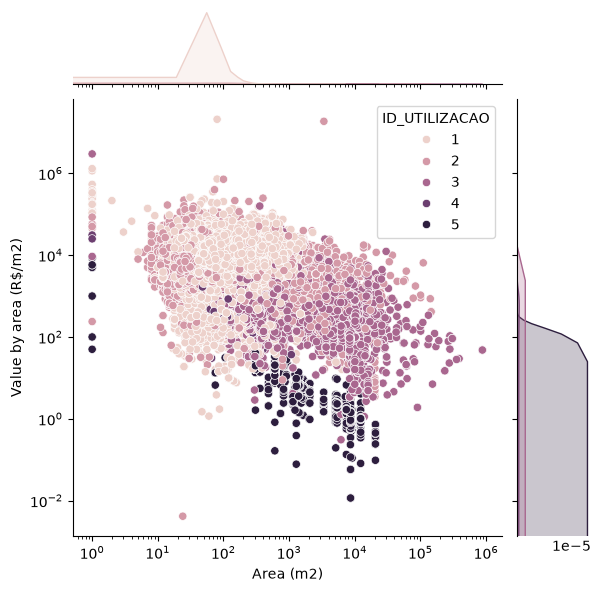

In [7]:
g = sns.jointplot(data=df, x="area", y="valor_m2", hue="ID_UTILIZACAO")

g.ax_joint.set_xscale("log")
g.ax_joint.set_yscale("log")

g.ax_joint.set_xlabel("Area (m2)")
g.ax_joint.set_ylabel("Value by area (R$/m2)")

Text(37.722222222222214, 0.5, 'Value (R$)')

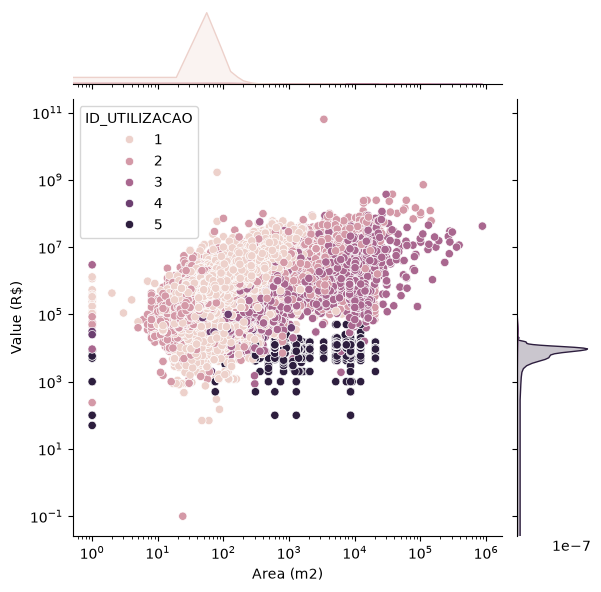

In [8]:
g = sns.jointplot(data=df, x="area", y="vl_declarado", hue="ID_UTILIZACAO")

g.ax_joint.set_xscale("log")
g.ax_joint.set_yscale("log")

g.ax_joint.set_xlabel("Area (m2)")
g.ax_joint.set_ylabel("Value (R$)")

The plots show several observations far from the main concentration of the data. 
Before continuing the analysis, it is useful to inspect the most extreme values, i.e., the outliers, directly.

In [9]:
df.sort_values("valor_m2", ascending=False).head(20)

,ano,mes,COD_REGIAO_FISCAL,COD_BAIRRO,COD_LOGRADOURO,COD_TRECHO,COD_TIPOLOGIA,ID_UTILIZACAO,FATOR_IDADE,vl_declarado,area,valor_m2
183272,2019,7,C,29,80986,1,10,1,0.63,1.670000e+09,80.0,2.087500e+07
181145,2019,7,A,110,148817,1,60,2,0.96,6.302690e+10,3384.0,1.862497e+07
319,2016,1,B,43,36376,1,1,3,NaN,2.975000e+06,1.0,2.975000e+06
48168,2025,12,C,128,9308,1,10,1,1.00,1.300000e+06,1.0,1.300000e+06
356012,2023,11,C,20,78881,1,10,1,1.00,1.149600e+06,1.0,1.149600e+06
90528,2017,9,B,121,23044,3,2,1,0.50,5.817628e+07,80.0,7.272035e+05
272302,2021,11,C,26,79368,1,94,2,0.82,7.155000e+07,100.0,7.155000e+05
344687,2023,8,C,5,63057,1,10,1,1.00,5.361624e+05,1.0,5.361624e+05
244899,2021,5,A,141,87049,97,52,2,0.88,2.900000e+07,73.0,3.972603e+05
355229,2023,11,B,115,120204,1,10,1,1.00,3.960000e+05,1.0,3.960000e+05


The largest values contain some observations that are difficult to justify as ordinary transactions.

The first two properties, both transferred in 2019, have declared values above R$ 1 billion. 
The first is an apartment in a high-value area, but its value is far above comparable properties of similar size. 
The second is an industrial property of about 3,000 m², but its value per square meter is still unusually high for the region.

The data also contain properties with areas close to 1 m², which are unlikely to represent typical real-estate transactions.

These extreme observations can strongly distort plots, summary statistics, and future models. 
The next cells therefore apply broad filters to remove clearly unrealistic values while keeping the normal variability of the market.

In [10]:
# removing outliers
_mask1 = df.area > 5   # super small area
_mask2 = df.area < 1e5 # super large area
_mask3 = df.valor_m2 > 0.1 # super low value/m2
_mask4 = df.valor_m2 < 120000 # super hight value/m2

# filtering
df = df[_mask1 & _mask2 & _mask3 & _mask4]

print(f"Samples with small area:", (~_mask1).sum())
print(f"Samples with large area:", (~_mask2).sum())
print(f"Samples with low value per m2:", (~_mask3).sum())
print(f"Samples with high value per m2:", (~_mask4).sum())

Samples with small area: 68
Samples with large area: 30
Samples with low value per m2: 16
Samples with high value per m2: 56


In [11]:
_mask1 = df.vl_declarado > 3e2 # super low total value
_mask2 = df.vl_declarado < 1e8 # super high total value

# filtering
df = df[_mask1 & _mask2]

print(f"Samples with low value:", (~_mask1).sum())
print(f"Samples with high value:", (~_mask2).sum())

Samples with low value: 5
Samples with high value: 15


## Relationship between total value and value per square meter

`vl_declarado` is the total declared transaction value, while `valor_m2` expresses the value relative to property area.
The following plot compares both variables after the most extreme observations have been removed. 
A logarithmic scale is again used because both variables remain strongly right-skewed.

Text(37.722222222222214, 0.5, 'Value per m2 (R$/M2)')

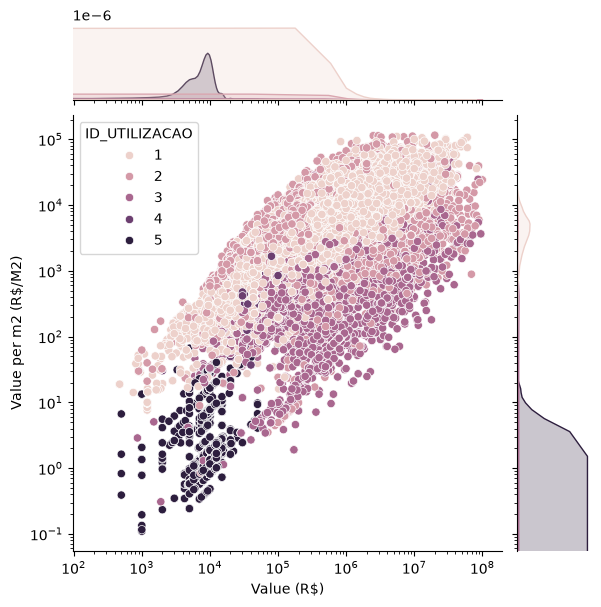

In [12]:
g = sns.jointplot(data=df, x="vl_declarado", y="valor_m2", hue="ID_UTILIZACAO")

g.ax_joint.set_xscale("log")
g.ax_joint.set_yscale("log")

g.ax_joint.set_xlabel("Value (R$)")
g.ax_joint.set_ylabel("Value per m2 (R$/M2)")

The relationship is not expected to be perfectly linear because total property value depends on more than value per square meter. 
Property area, location, typology, age, and usage can all affect the final transaction value.

This distinction will be important later when choosing the prediction target and the features used by the machine-learning models.

## Seasonality

Real-estate activity may vary during the year. 
To check for a seasonal pattern, the next plot shows the average monthly evolution of `valor_m2` for each property-usage category and year.

The facets are separated by `ID_UTILIZACAO` because residential, non-residential, land, parking, and common-area transactions can behave differently.

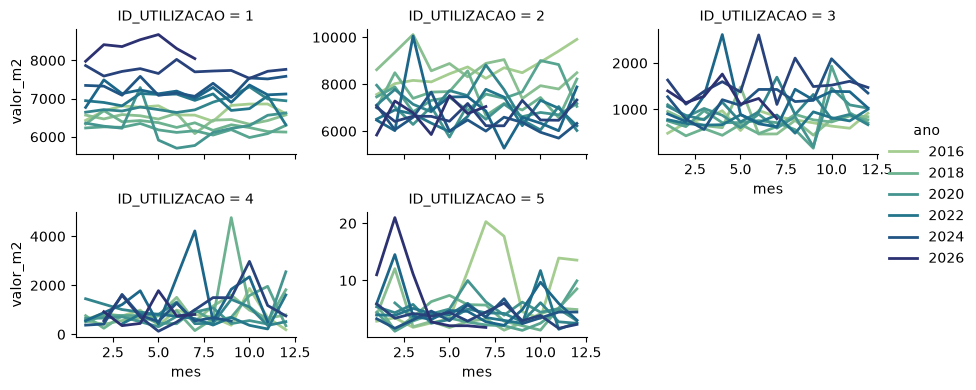

In [13]:
g = sns.relplot(
    data=df,
    x="mes", y="valor_m2", hue="ano", col="ID_UTILIZACAO",
    kind="line", palette="crest", linewidth=2, zorder=5,
    col_wrap=3, height=2, aspect=1.5, legend=True, errorbar=None, facet_kws=dict(sharey=False)
)

There is some month-to-month variation, but no single seasonal pattern is consistently visible across all years and property categories.

This suggests that seasonality may exist, but its effect is smaller or less stable than the broader differences between years and property types.

## Evolution over time

The next plots examine how the market changes from year to year.

Two views are used:

- the median valor_m2, which is less sensitive to extreme transactions than the mean;
- transaction activity, shown together with the declared transaction values.

The analysis is first separated by property usage and then by fiscal region. 
This helps reveal whether price evolution is similar across different market segments and locations.

Text(0, 0.5, 'Total volume (R$)')

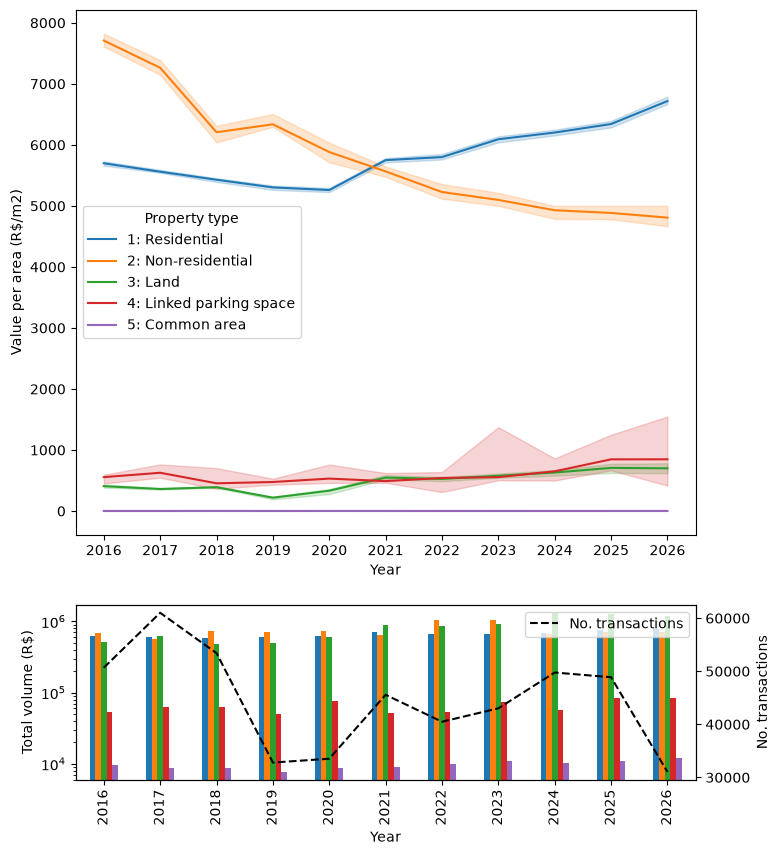

In [14]:
hue = "ID_UTILIZACAO"

fig, axes = plt.subplots(nrows=2, figsize=(8, 10), height_ratios=[3,1])

ax = axes[0]
sns.lineplot(
    data=df,
    x="ano", y="valor_m2",
    hue=hue,
    estimator=np.median,
    palette='tab10',
    ax=ax
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    ["1: Residential","2: Non-residential","3: Land","4: Linked parking space","5: Common area"],
    title="Property type"
)
ax.set_xticks(df.ano.unique())
ax.set_xlabel("Year")
ax.set_ylabel("Value per area (R$/m2)")

ax = axes[1]
_df_temp = df.groupby(["ano", hue]).vl_declarado.mean().unstack()
_df_temp.plot.bar(ax=ax, legend=False, logy=True)
ax_counts = ax.twinx()
ax_counts.set_ylabel("No. transactions")
df.groupby("ano").count().reset_index(drop=True).valor_m2.plot(ax=ax_counts, legend=True,ls="--", color="k")
ax_counts.legend(["No. transactions"])

ax.set_xlabel("Year")
ax.set_ylabel("Total volume (R$)")

Text(0, 0.5, 'Total volume (R$)')

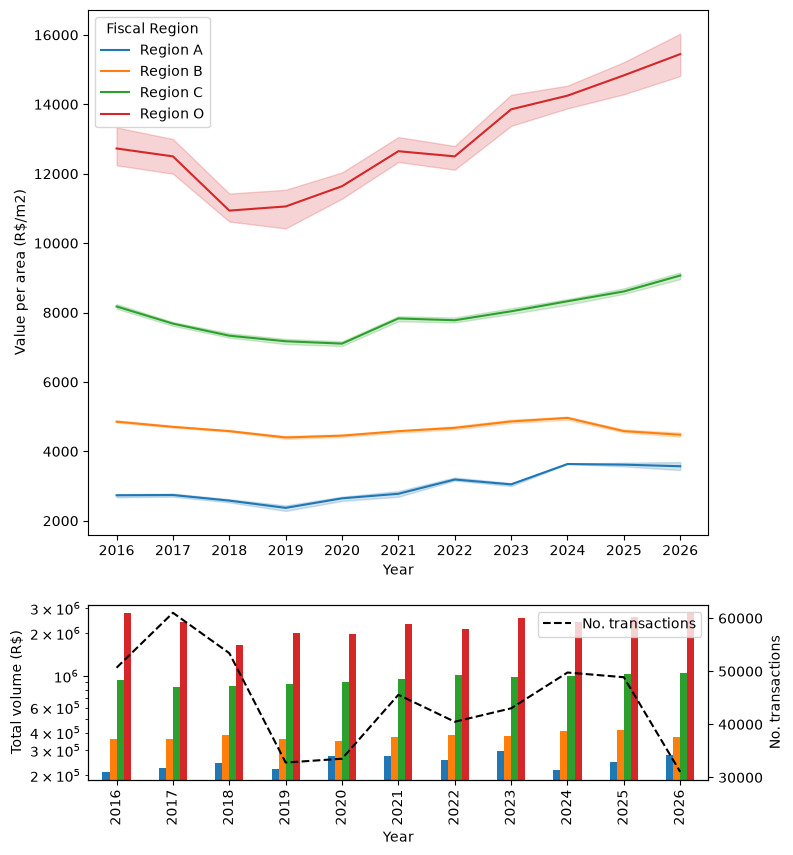

In [15]:
hue = "COD_REGIAO_FISCAL"

fig, axes = plt.subplots(nrows=2, figsize=(8, 10), height_ratios=[3,1])

ax = axes[0]
sns.lineplot(
    data=df,
    x="ano", y="valor_m2",
    hue=hue,
    estimator=np.median, # median is less sensitive to high outliers
    palette='tab10',
    ax=ax
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    ["Region A","Region B","Region C","Region O"],
    title="Fiscal Region"
)
ax.set_xticks(df.ano.unique())
ax.set_xlabel("Year")
ax.set_ylabel("Value per area (R$/m2)")

ax = axes[1]
_df_temp = df.groupby(["ano", hue]).vl_declarado.mean().unstack()
_df_temp.plot.bar(ax=ax, legend=False, logy=True)
ax_counts = ax.twinx()
ax_counts.set_ylabel("No. transactions")
df.groupby("ano").count().reset_index(drop=True).valor_m2.plot(ax=ax_counts, legend=True,ls="--", color="k")
ax_counts.legend(["No. transactions"])

ax.set_xlabel("Year")
ax.set_ylabel("Total volume (R$)")

## Category Frequency
Before using categorical variables in a model, it is useful to understand how frequently each category appears.

The next tables and plots show the number of transactions by year for:
- fiscal region;
- property typology;
- neighborhood;
- property usage.

This also helps identify categories with very few observations and categories that dominate the dataset.

In [16]:
# região fiscal
df_fiscal_counts = df.groupby(["ano", "COD_REGIAO_FISCAL"]).count().valor_m2.unstack().T
df_fiscal_counts["ALL"] = df_fiscal_counts.sum(axis=1)
df_fiscal_counts = df_fiscal_counts.sort_values("ALL", ascending=True)
df_fiscal_counts

ano,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,ALL
COD_REGIAO_FISCAL,,,,,,,,,,,,
O,781,1067,701,418,759,1213,1121,1104,1214,1338,778,10494
A,5003,6119,5058,3532,3161,3803,4156,4166,6239,5541,3124,49902
B,23356,25859,22832,13529,14072,18539,16768,18309,20465,18414,11160,203303
C,21527,27970,24822,15320,15527,22013,18442,19435,21843,23583,15979,226461


<Axes: ylabel='COD_REGIAO_FISCAL'>

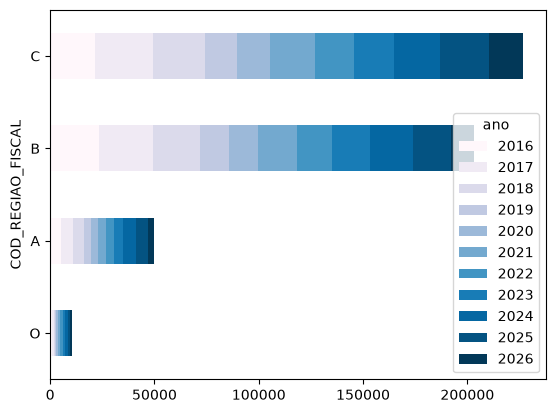

In [17]:
df_fiscal_counts.drop("ALL", axis=1).plot.barh(stacked=True, cmap='PuBu')

In [18]:
# tipologia
df_type_counts = df.groupby(["ano", "COD_TIPOLOGIA"]).count().valor_m2.unstack().T
df_type_counts["ALL"] = df_type_counts.sum(axis=1)
df_type_counts = df_type_counts.sort_values("ALL", ascending=True)
df_type_counts.index = df_tipologia.loc[df_type_counts.index].ds_imovel_tipologia
df_type_counts

ano,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,ALL
ds_imovel_tipologia,,,,,,,,,,,,
CINEMA/TEATRO,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,1.0,1.0,1.0,6.0
GARAGEM/ESTACIONAMENTO,NaN,NaN,3.0,NaN,4.0,2.0,3.0,9.0,3.0,1.0,1.0,26.0
TELHEIRO ANEXO,4.0,10.0,2.0,NaN,1.0,NaN,NaN,9.0,1.0,NaN,NaN,27.0
HOSPITAL/CLINICA C/INTERNACAO,1.0,1.0,2.0,3.0,2.0,4.0,2.0,4.0,6.0,9.0,1.0,35.0
CONSTR SEC,NaN,4.0,NaN,1.0,2.0,4.0,5.0,7.0,4.0,4.0,4.0,35.0
TELHEIRO,NaN,2.0,2.0,5.0,NaN,5.0,2.0,9.0,3.0,8.0,NaN,36.0
ARMAZEM/DEPOSITO,4.0,8.0,NaN,2.0,4.0,6.0,8.0,2.0,5.0,3.0,3.0,45.0
PROLETARIO CASA,11.0,14.0,8.0,16.0,10.0,10.0,NaN,NaN,NaN,NaN,3.0,72.0
COLEGIO/CRECHE,6.0,12.0,17.0,12.0,9.0,15.0,13.0,16.0,21.0,24.0,8.0,153.0


<Axes: ylabel='ds_imovel_tipologia'>

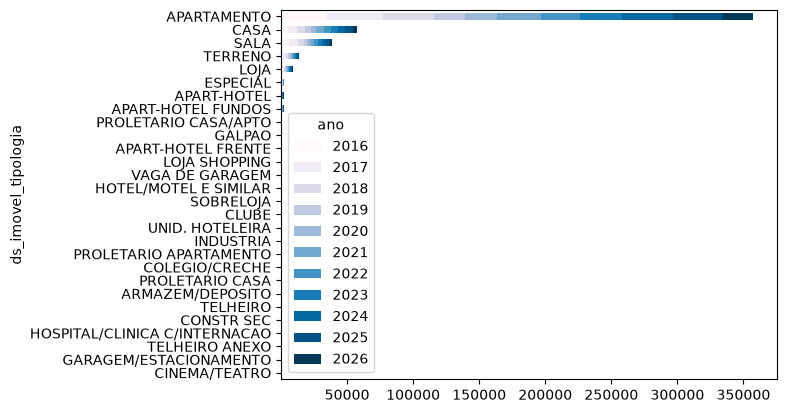

In [19]:
df_type_counts.drop("ALL", axis=1).plot.barh(stacked=True, cmap='PuBu')

In [20]:
# bairro
df_bairro_counts = df.groupby(["ano", "COD_BAIRRO"]).count().valor_m2.unstack().T
df_bairro_counts["ALL"] = df_bairro_counts.sum(axis=1)
df_bairro_counts = df_bairro_counts.join(df_bairro).set_index("nm_bairro_norm")
df_bairro_counts = df_bairro_counts.sort_values("ALL")
df_bairro_counts

,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,ALL
nm_bairro_norm,,,,,,,,,,,,
GALEAO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0
GRUMARI,2.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0
ROCINHA,2.0,NaN,NaN,1.0,NaN,NaN,1.0,1.0,NaN,2.0,NaN,7.0
ILHA DE GUARATIBA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,8.0
DEODORO,3.0,2.0,NaN,2.0,1.0,NaN,1.0,1.0,1.0,NaN,NaN,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...
CAMPO GRANDE,2137.0,2751.0,2209.0,1357.0,1585.0,1820.0,1786.0,1707.0,2400.0,2020.0,1242.0,21014.0
JACAREPAGUA,2984.0,3775.0,4015.0,2101.0,2081.0,2718.0,2001.0,2064.0,2086.0,2041.0,730.0,26596.0
COPACABANA,2152.0,2713.0,2718.0,1850.0,1731.0,2368.0,2427.0,2652.0,2957.0,3517.0,2174.0,27259.0


<Axes: ylabel='nm_bairro_norm'>

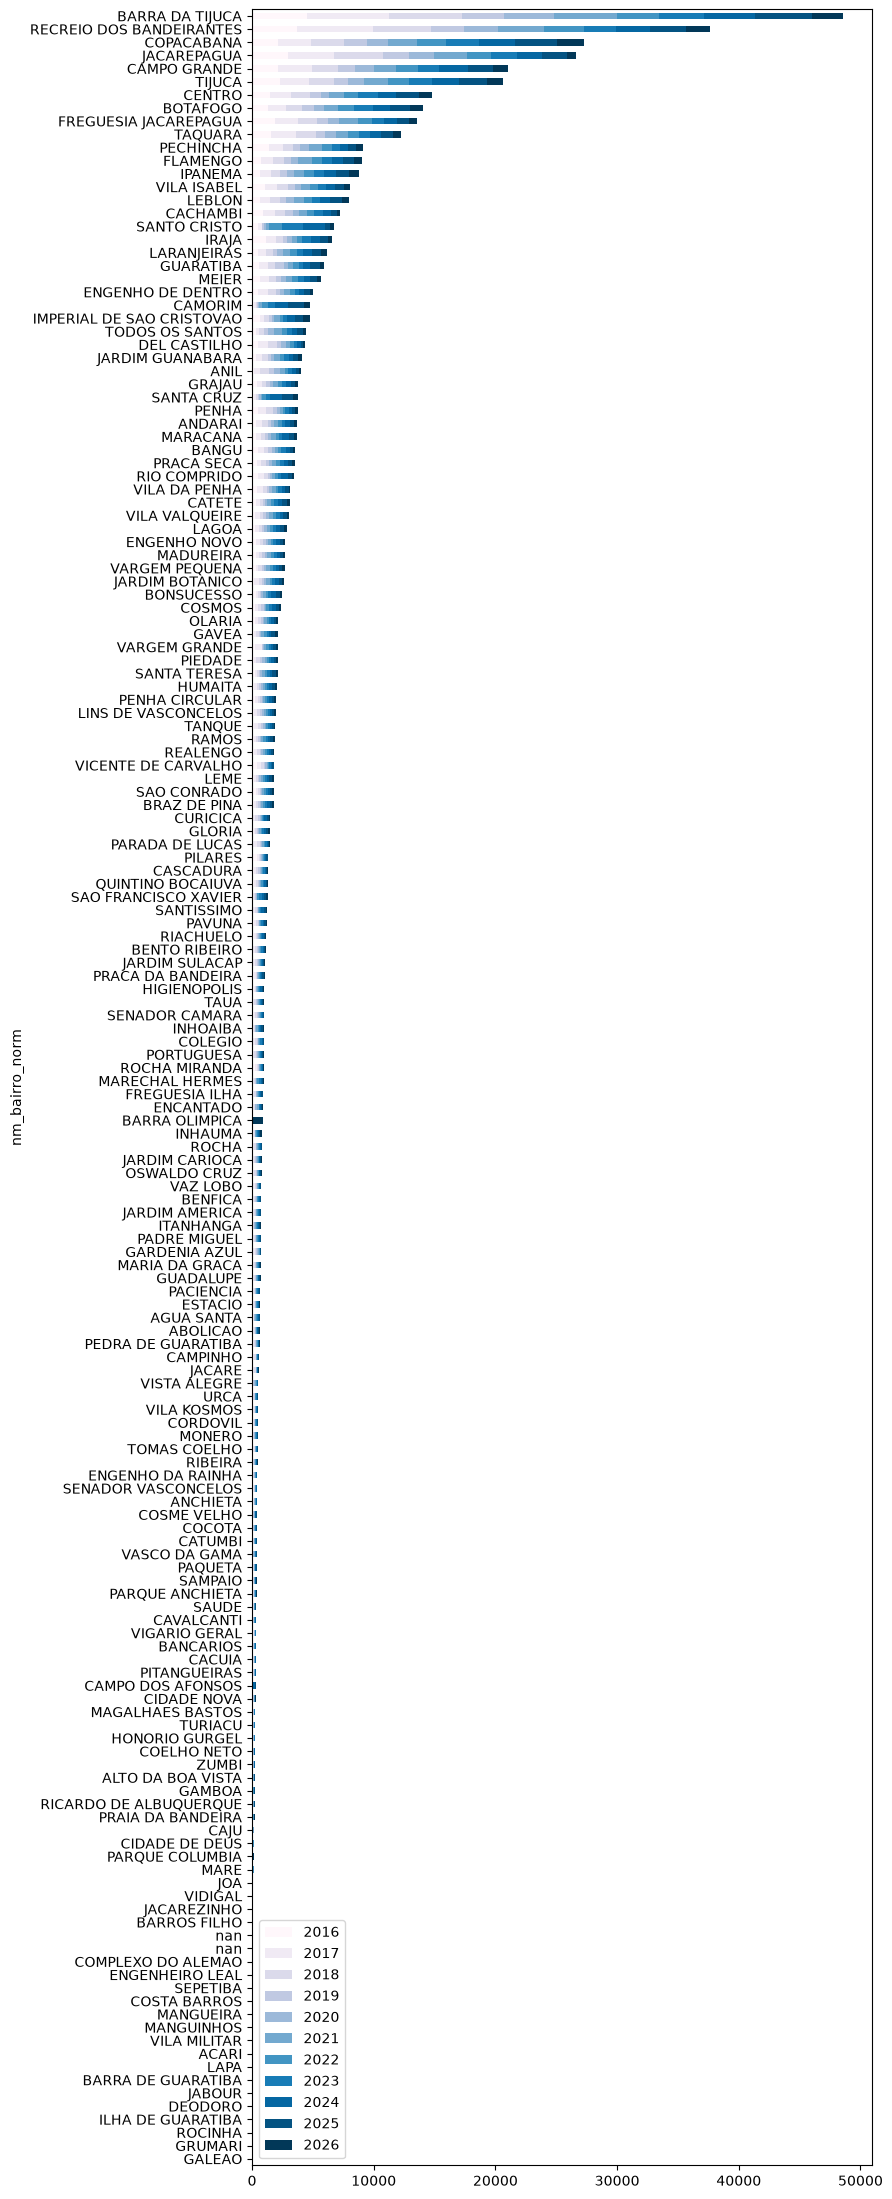

In [21]:
fig, ax = plt.subplots(figsize=(8, 28))

df_bairro_counts.drop("ALL", axis=1).plot.barh(stacked=True, cmap='PuBu', ax=ax)

In [22]:
# utilização
df_util_counts = df.groupby(["ano", "ID_UTILIZACAO"]).count().valor_m2.unstack().T
df_util_counts["ALL"] = df_util_counts.sum(axis=1)
df_util_counts = df_util_counts.sort_values("ALL", ascending=True)
df_util_counts.index = df_descricao.loc[df_util_counts.index].DESCRICAO
df_util_counts

ano,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,ALL
DESCRICAO,,,,,,,,,,,,
VAGA VINCULADA,115,90,85,50,37,57,24,21,25,33,15,552
AREA COMUM,390,330,461,184,132,342,168,145,154,122,55,2483
TERRITORIAL,1403,1782,1276,1151,1244,984,811,847,842,924,535,11799
NAO RESIDENCIAL,8186,8946,6118,3687,3292,4355,3974,4446,4393,4675,2446,54518
RESIDENCIAL,40573,49867,45473,27727,28814,39830,35510,37555,44347,43122,27990,420808


<Axes: ylabel='DESCRICAO'>

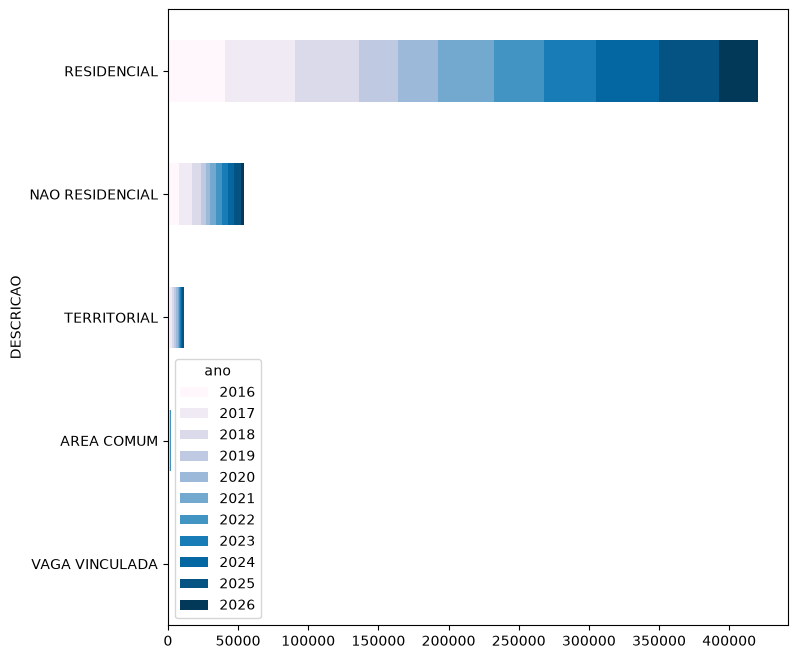

In [23]:
fig, ax = plt.subplots(figsize=(8, 8))

df_util_counts.drop("ALL", axis=1).plot.barh(stacked=True, cmap='PuBu', ax=ax)

In [37]:
df_util_counts.ALL / df_util_counts.ALL.sum()

DESCRICAO
VAGA VINCULADA     0.001126
AREA COMUM         0.005066
TERRITORIAL        0.024072
NAO RESIDENCIAL    0.111225
RESIDENCIAL        0.858512
Name: ALL, dtype: float64

## Feature distributions
The shape of each numerical distribution affects how easy it is to visualize and model the data.

Property values and areas are strongly right-skewed, so the next histograms inspect their logarithms. A log transformation compresses very large values and makes proportional differences easier to compare.

`FATOR_IDADE` is inspected on its original scale because it is already a bounded valuation factor rather than a monetary or size variable.

In [24]:
import numpy as np

Text(0, 0.5, 'Density')

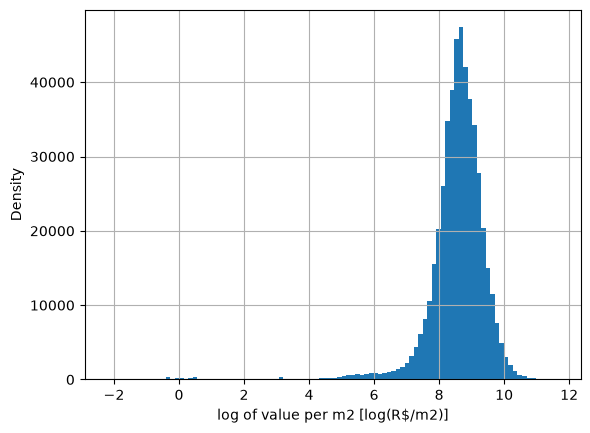

In [25]:
ax = df.valor_m2.apply(np.log).hist(bins=100)
ax.set_xlabel("log of value per m2 [log(R$/m2)]")
ax.set_ylabel("Density")

Text(0, 0.5, 'Density')

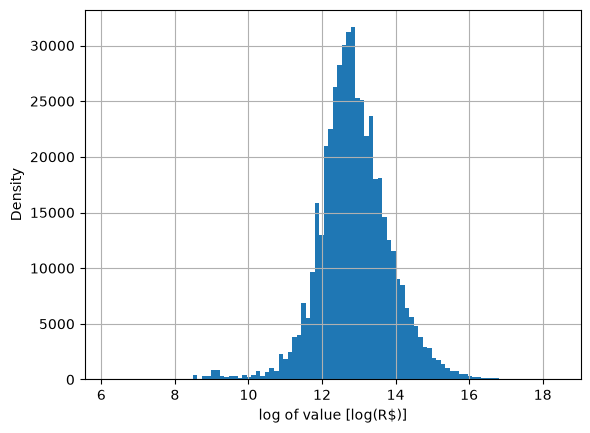

In [26]:
ax = df.vl_declarado.apply(np.log).hist(bins=100)
ax.set_xlabel("log of value [log(R$)]")
ax.set_ylabel("Density")

Text(0, 0.5, 'Density')

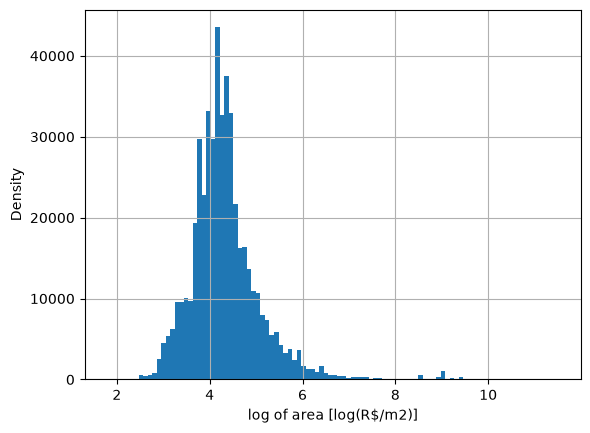

In [27]:
ax = df.area.apply(np.log).hist(bins=100)
ax.set_xlabel("log of area [log(R$/m2)]")
ax.set_ylabel("Density")

Text(0, 0.5, 'Density')

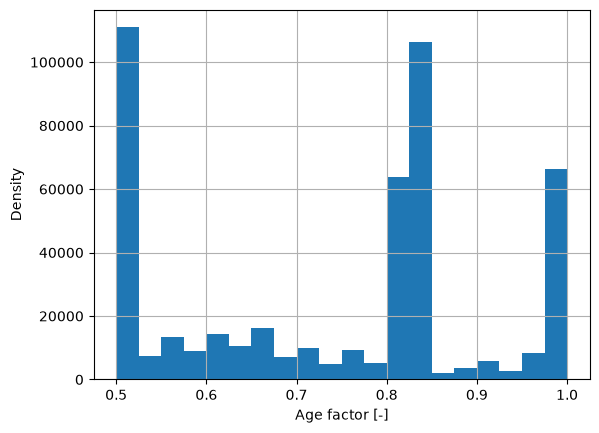

In [28]:
ax = df.FATOR_IDADE.hist(bins=20)
ax.set_xlabel("Age factor [-]")
ax.set_ylabel("Density")

`FATOR_IDADE` does not resemble a simple standard distribution, even after considering possible transformations. 
This is not necessarily a problem. 
Tree-based models do not require normally distributed inputs, so the feature can be kept in its original form.

The logarithms of `valor_m2`, `vl_declarado`, and `area` are much more symmetric than their original distributions. 
This indicates that these variables are approximately log-normal at the global level.

The next plots check whether this pattern also holds within smaller groups of the data.

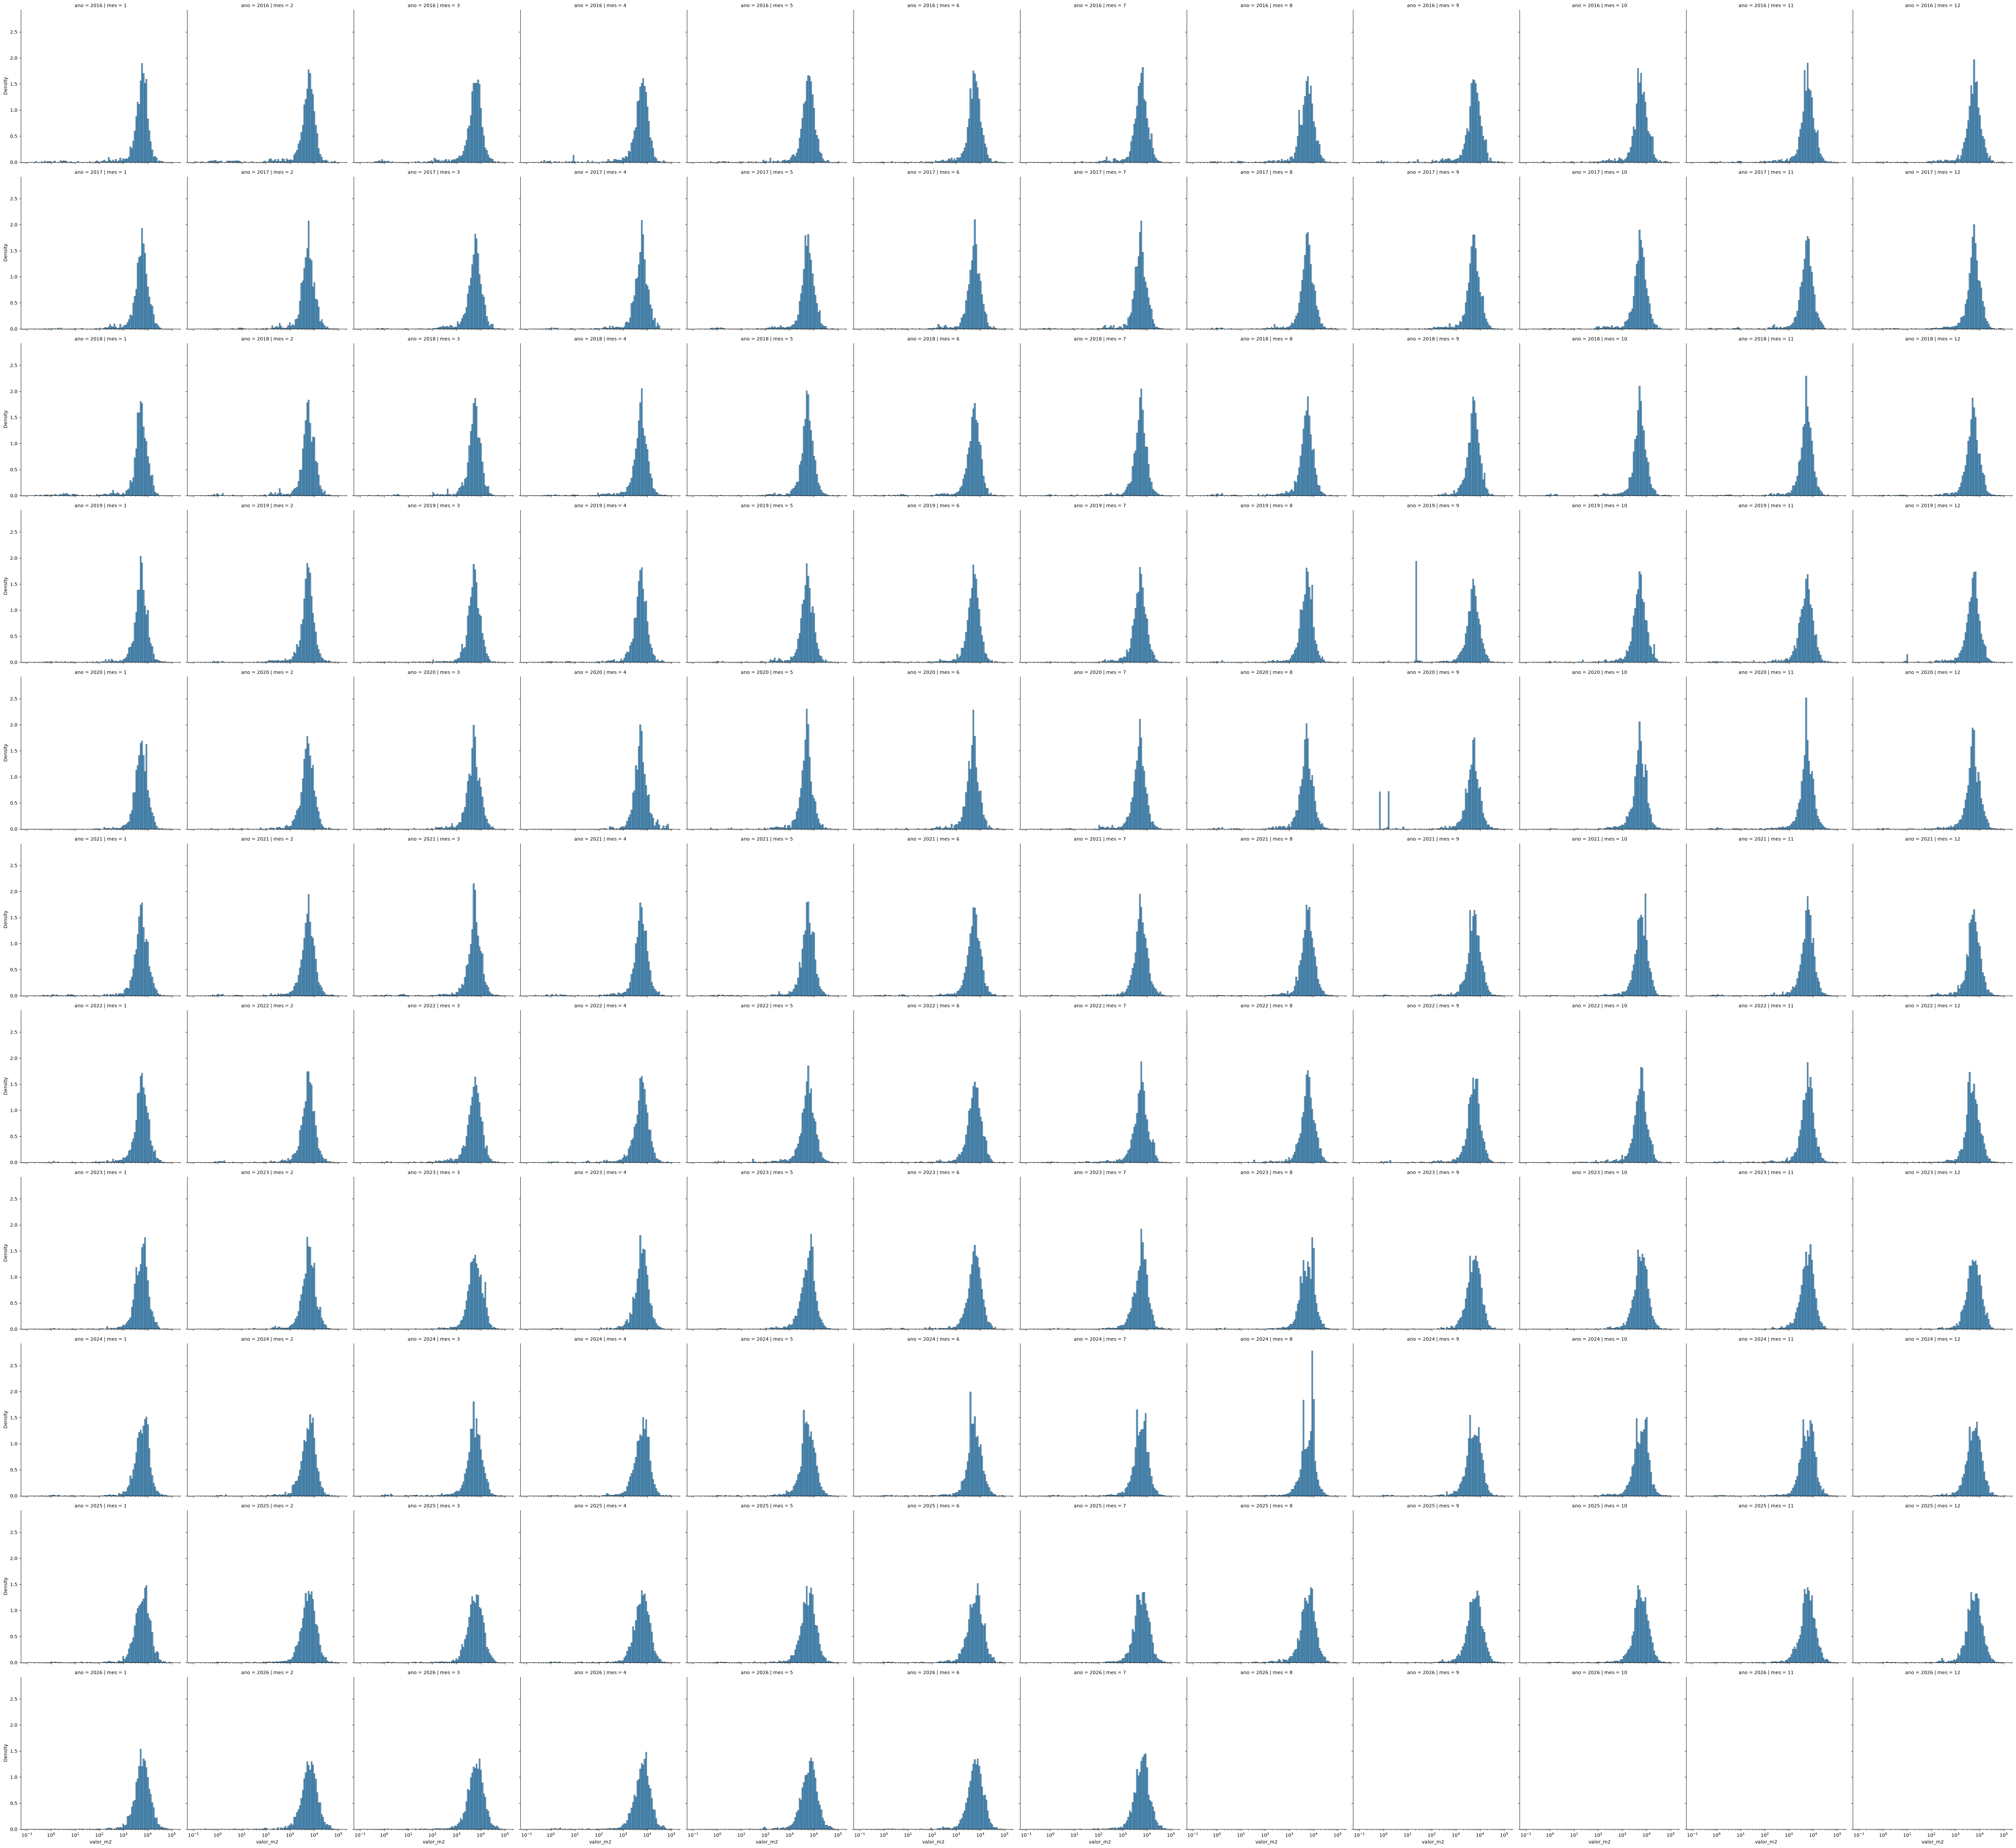

In [29]:
g = sns.displot(df, x="valor_m2", row="ano", col="mes", log_scale=True, stat="density", common_norm=False, bins=100)

When the data are separated by year and month, the distributions of `valor_m2` remain broadly similar on the logarithmic scale.

This suggests that the strong right-skew is not caused by only a few isolated periods. 
It is a recurring characteristic of the transaction data.

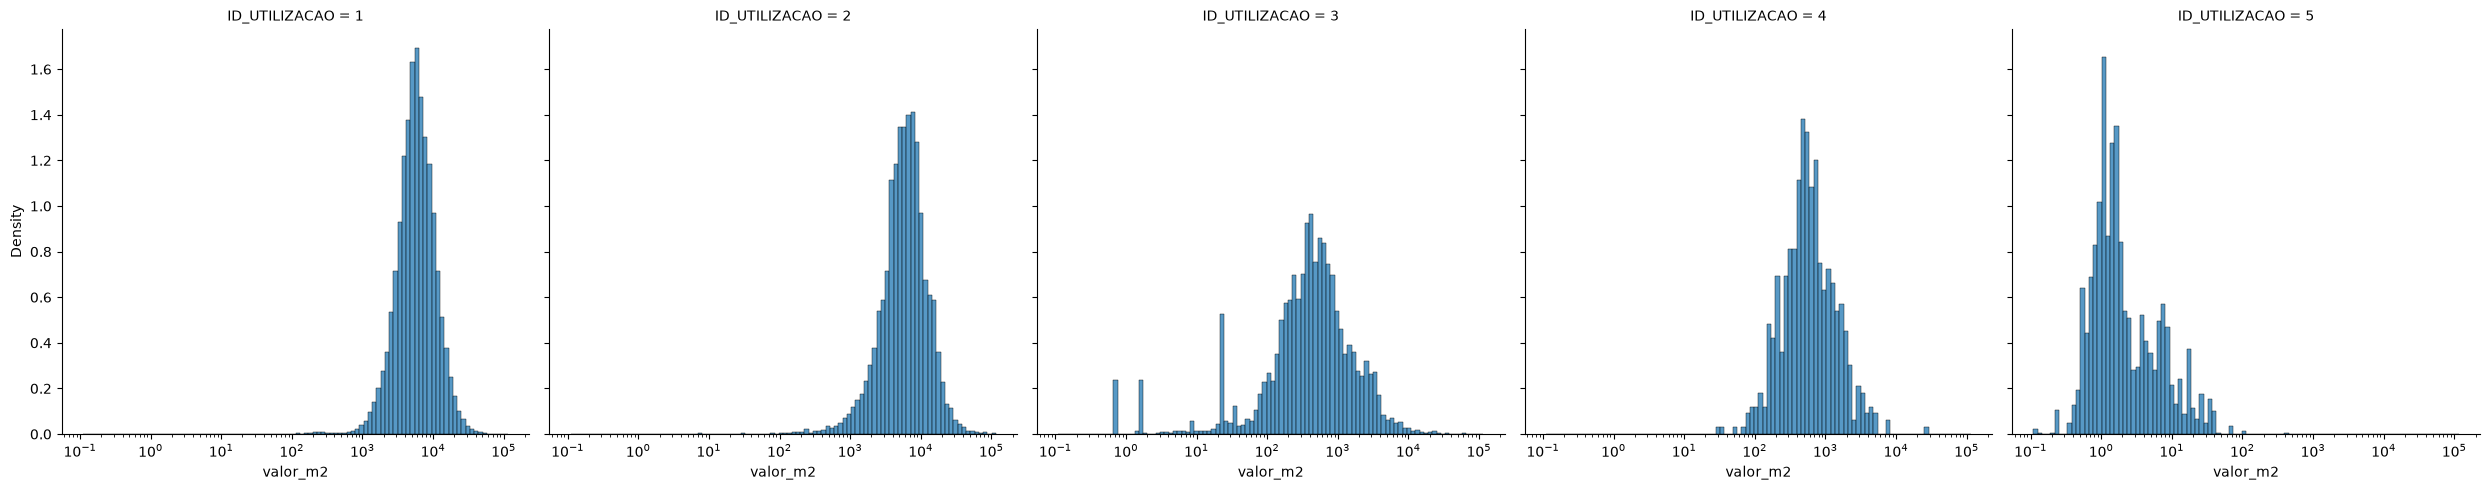

In [30]:
g = sns.displot(df, x="valor_m2", col="ID_UTILIZACAO", log_scale=True, stat="density", common_norm=False, bins=100)

A similar pattern appears when the data are grouped by property usage (`ID_UTILIZACAO`). 
The residential (`1`) and non-residential (`2`) categories, which contain most transactions, show particularly clear log-shaped distributions.

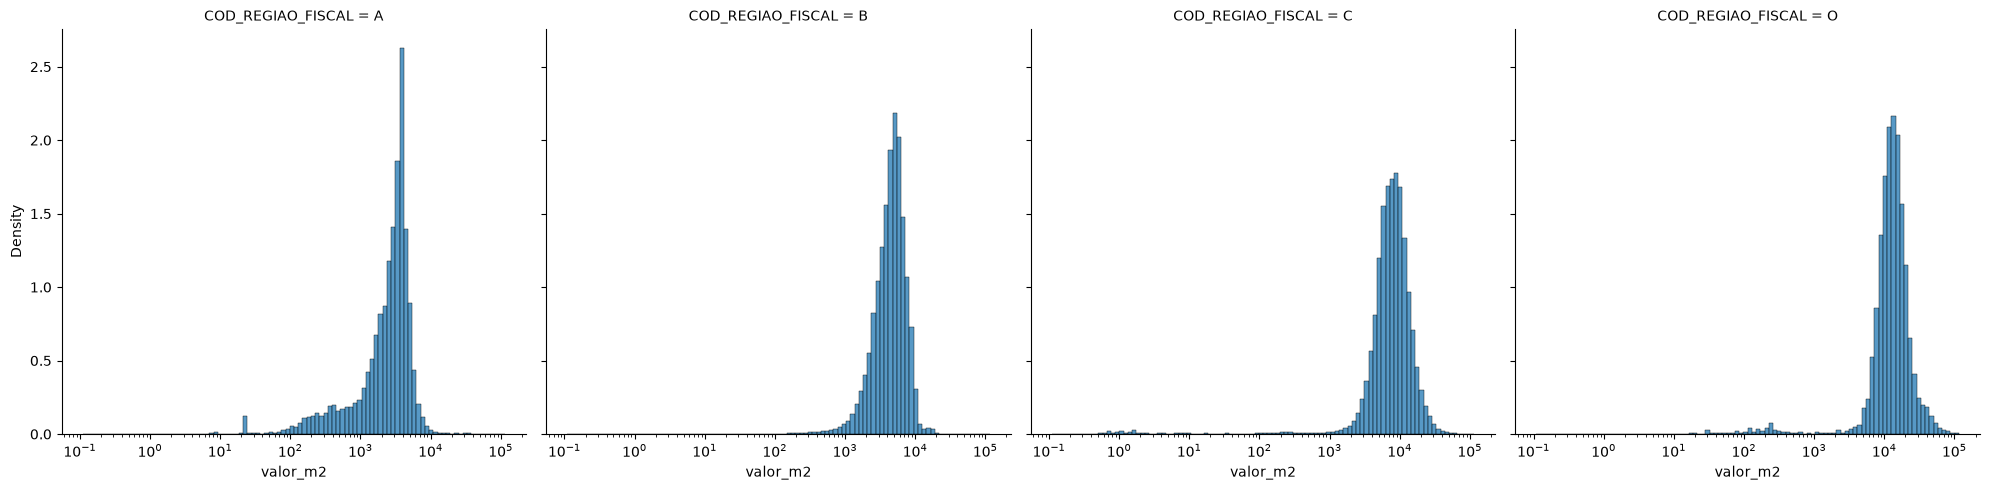

In [31]:
g = sns.displot(df, x="valor_m2", col="COD_REGIAO_FISCAL", log_scale=True, stat="density", common_norm=False, bins=100)

The same general pattern appears across fiscal regions.

Region A has a somewhat different shape, but `valor_m2` is still much easier to interpret on a logarithmic scale than on its original scale.

This observation can be useful later. 
Log transformations often help when working with strongly skewed variables, especially in models that are sensitive to scale, distance, or linear relationships.

# Feature engineering

The EDA shows that property values change over time and that the market level also depends on the property category and location.

Two temporal effects are therefore relevant for later modeling:
- seasonality, which represents possible differences between months;
- market drift, which represents changes in the general price level from one period to another.

The following cells prepare a first set of historical market statistics while keeping the original transaction data unchanged.

In [32]:
df_featured = df.copy()

## Seasonality

Seasonality will be handled later inside the modeling pipeline. 
Keeping this transformation in the pipeline makes training and prediction follow the same preprocessing steps.

## Market drift
To represent the recent market level, the next cell calculates summary statistics of `valor_m2` for each property-usage category.

The statistics are shifted forward by one year before being joined to the transaction table. 
Therefore, a transaction in year `t` receives statistics calculated from year `t-1`.
The generated features are:
- `count_anterior`: number of transactions in the previous year;
- `median_anterior`: median value per square meter in the previous year;
- `mean_anterior`: mean value per square meter in the previous year;
- `std_anterior`: standard deviation of value per square meter in the previous year.

Using only previous-year information avoids using future observations when these features are later evaluated in a temporal prediction setting.

In [33]:
# get the stats of previous 
df_temp = df.copy()
df_temp.ano = df_temp.ano + 1 # to be used in the next year !!!!!
df_temp = df_temp.groupby(["ano", "ID_UTILIZACAO"]).valor_m2.agg(["count", np.median, np.mean, np.std])
df_temp.columns = ['count_anterior', 'median_anterior', 'mean_anterior', 'std_anterior']

df_featured = df_featured.join(df_temp, on=["ano", "ID_UTILIZACAO"])

# Saving the featured dataset
The transaction table with the additional historical features is saved together with the lookup tables in a new Excel workbook.

This file becomes the input for the next stages of the project, where the features and prediction models can be tested more systematically.

In [34]:
savefile_path = "../data/processed/ITBI_featured.xlsx"

with pd.ExcelWriter(savefile_path, engine="openpyxl") as writer:
    df_featured.to_excel(writer, sheet_name="transacoes")
    df_bairro.to_excel(writer, sheet_name="bairro")
    df_logradouro.to_excel(writer, sheet_name="logradouro")
    df_tipologia.to_excel(writer, sheet_name="tipologia")
    df_descricao.to_excel(writer, sheet_name="descricao")